# AnyCam — 03b · Step 5: improved baseline (bigger images + stronger augmentation)

First run (ResNet18, plain): cultivar accuracy 0.73, overfitting after epoch 7.
This notebook tries two fixes on the same official split:
- **A**: ResNet18, images enlarged 2x inside the model, stronger augmentation
- **B**: ConvNeXt-Tiny (closer to the paper's best model), same settings

Same setup as notebook 03: **Add Input → HyperLeaf2024 (trophy)**, **GPU T4 x2**, **Internet On**.
Run All (~30-40 min). Then save to GitHub as `kaggle_runs/03b_step5_improved_baseline.ipynb`.

In [1]:
import os, subprocess, glob, json, pathlib
REPO = 'https://github.com/ShahnawazQ007/one-model-many-camera.git'
if not os.path.exists('/kaggle/working/anycam'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', REPO, '/kaggle/working/anycam'], check=True)
else:
    subprocess.run(['git', '-C', '/kaggle/working/anycam', 'pull', '-q'], check=True)
os.chdir('/kaggle/working/anycam')
!pip -q install timm tifffile imagecodecs
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - turn on the GPU accelerator!')
hits = [os.path.dirname(f) for f in glob.glob('/kaggle/input/**/train.csv', recursive=True)
        if os.path.isdir(os.path.join(os.path.dirname(f), 'images'))]
assert hits, 'Add Input -> search hyperleaf -> the one with the trophy icon'
DATA = hits[0]; print('data:', DATA, '| images:', len(glob.glob(f'{DATA}/images/*.tiff')))

GPU: Tesla T4
data: /kaggle/input/competitions/HyperLeaf2024 | images: 2410


In [2]:
# A: ResNet18, 2x larger images, stronger augmentation
!python experiments/train_baseline.py --data {DATA} --split official --upscale 2 --aug strong --epochs 50 --patience 12 --out runs/A_resnet18_up2_strong

device cuda | train 1410 val 180 test 820 leaves

model.safetensors: downloading bytes: █▏                    | 2.53MB            
model.safetensors: downloading bytes: ████████████▎         | 26.2MB,   ???B/s  
model.safetensors: downloading bytes: ██████████████████████| 44.0MB, 4.32MB/s  
model.safetensors: reconstructing file: 100%|██████| 46.8MB / 46.8MB, 4.61MB/s  
model resnet18: 11.81M parameters
epoch  0 train 2.223 val 2.295 (84s)
epoch  1 train 1.774 val 1.710 (157s)
epoch  2 train 1.455 val 1.394 (230s)
epoch  3 train 1.211 val 1.446 (303s)
epoch  4 train 1.025 val 1.246 (375s)
epoch  5 train 0.864 val 1.304 (447s)
epoch  6 train 0.796 val 1.180 (519s)
epoch  7 train 0.707 val 1.263 (590s)
epoch  8 train 0.629 val 1.448 (661s)
epoch  9 train 0.608 val 1.166 (732s)
epoch 10 train 0.558 val 1.305 (803s)
epoch 11 train 0.522 val 1.263 (875s)
epoch 12 train 0.491 val 1.405 (945s)
epoch 13 train 0.492 val 1.346 (1015s)
epoch 14 train 0.466 val 1.439 (1085s)
epoch 15 train 0.444 

In [3]:
# B: ConvNeXt-Tiny, 2x larger images, stronger augmentation (smaller batch to fit GPU memory)
!python experiments/train_baseline.py --data {DATA} --split official --backbone convnext_tiny --upscale 2 --aug strong --batch 16 --lr 1e-4 --epochs 50 --patience 12 --out runs/B_convnext_tiny_up2_strong

device cuda | train 1410 val 180 test 820 leaves

model.safetensors: downloading bytes: ████████              | 41.9MB, 2.27MB/s  
model.safetensors: downloading bytes: ███████████████▉      | 82.8MB, 5.25MB/s  
model.safetensors: downloading bytes: ██████████████████████|  109MB, 10.4MB/s  
model.safetensors: reconstructing file: 100%|██████|  114MB /  114MB, 11.1MB/s  
model convnext_tiny: 28.14M parameters
epoch  0 train 2.839 val 2.986 (80s)
epoch  1 train 2.304 val 2.605 (151s)
epoch  2 train 1.925 val 2.283 (220s)
epoch  3 train 1.737 val 1.549 (292s)
epoch  4 train 1.386 val 1.789 (365s)
epoch  5 train 1.245 val 1.540 (436s)
epoch  6 train 1.003 val 1.250 (509s)
epoch  7 train 0.863 val 2.032 (580s)
epoch  8 train 0.838 val 1.359 (651s)
epoch  9 train 0.651 val 1.695 (722s)
epoch 10 train 0.587 val 1.018 (793s)
epoch 11 train 0.555 val 0.854 (865s)
epoch 12 train 0.486 val 1.559 (938s)
epoch 13 train 0.463 val 1.556 (1009s)
epoch 14 train 0.407 val 2.132 (1080s)
epoch 15 train 0

                       run    split      backbone  upscale    aug  best_epoch  cultivar_acc  cultivar_F1  GrainWeight_R2  Gsw_R2  PhiPS2_R2  Fertilizer_R2
     A_resnet18_up2_strong official      resnet18      2.0 strong           9         0.821        0.805           0.584   0.077      0.524          0.759
B_convnext_tiny_up2_strong official convnext_tiny      2.0 strong          11         0.768        0.764           0.714   0.037      0.471          0.785
saved runs/A_resnet18_up2_strong/figures.png
saved runs/B_convnext_tiny_up2_strong/figures.png
runs/A_resnet18_up2_strong/figures.png


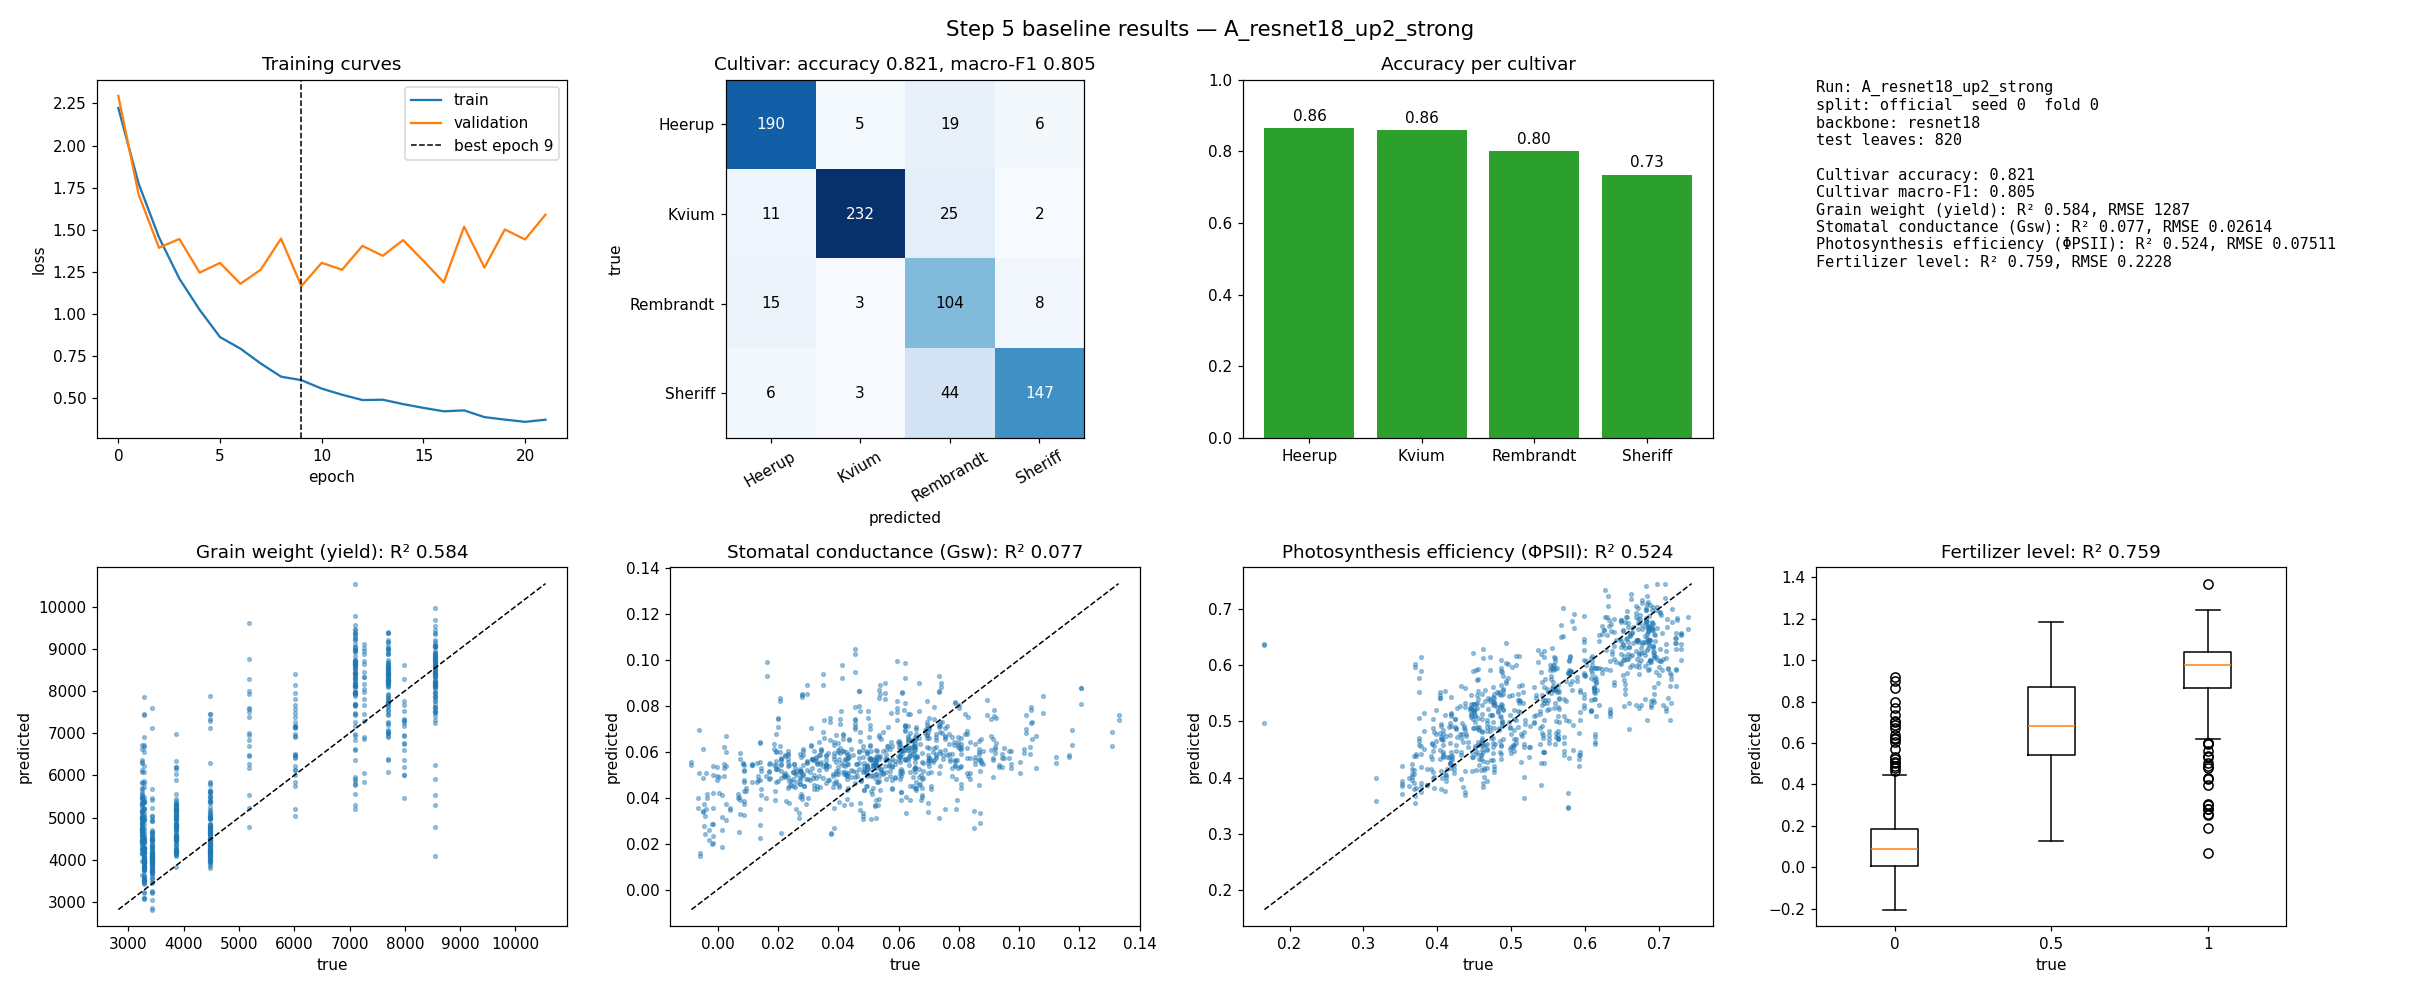

runs/B_convnext_tiny_up2_strong/figures.png


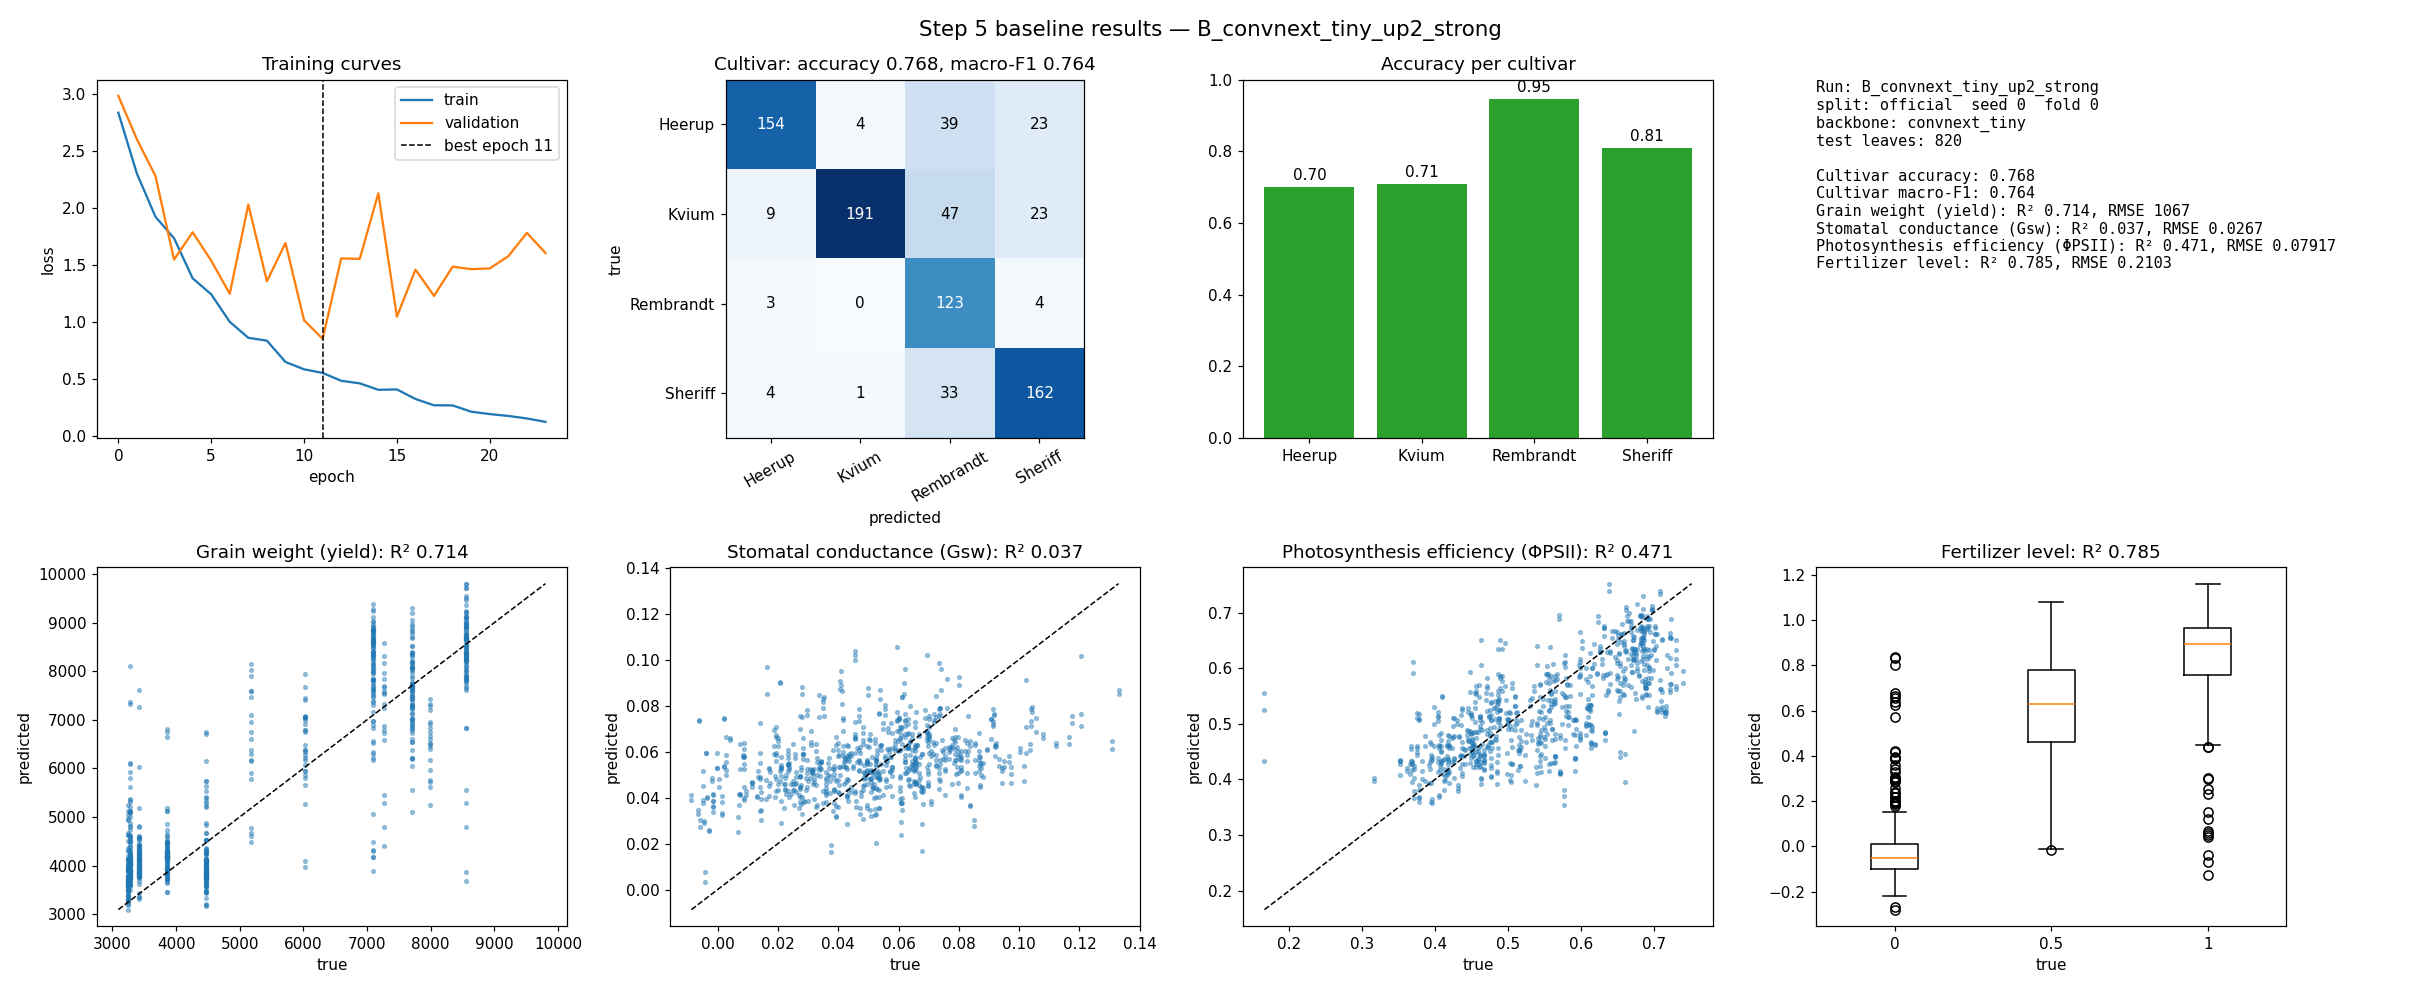

In [4]:
# comparison table + figures
!python scripts/compare_runs.py runs/*
!python scripts/plot_run.py runs/*
from IPython.display import Image, display
for f in sorted(glob.glob('runs/*/figures.png')):
    print(f); display(Image(f))

## Done
Wait until every cell has finished, then in the right panel **GitHub → File** type
`kaggle_runs/03b_step5_improved_baseline.ipynb` → **Save**. Tell Claude "done".